# Dataset QA and exploratory analysis

This notebook presents the locked synthetic PBR material dataset contract, verification status, class/split counts, pooled RGB statistics, and representative EDA figures. It uses the canonical manifests and generated reports; it does not train models or evaluate model performance.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if (not (ROOT / 'metadata/render_manifest.csv').is_file()
        and (ROOT.parent / 'metadata/render_manifest.csv').is_file()):
    ROOT = ROOT.parent
assert (ROOT / 'metadata/render_manifest.csv').is_file(), (
    'Run this notebook from the repository root.'
)
sys.path.insert(0, str(ROOT / 'src'))
from material_classifier.data import load_render_manifest  # noqa: E402

VALIDATION_PATH = ROOT / 'reports/results/dataset_validation.json'
SUMMARY_PATH = ROOT / 'reports/results/dataset_summary.csv'
FIGURE_DIR = ROOT / 'reports/figures/dataset'
validation = json.loads(VALIDATION_PATH.read_text(encoding='utf-8'))
summary = pd.read_csv(SUMMARY_PATH)
rows = load_render_manifest(ROOT / 'metadata/render_manifest.csv')
display(Markdown(
    '**Notebook scope:** metadata QA and descriptive EDA only; no model or performance evaluation.'
))

**Notebook scope:** metadata QA and descriptive EDA only; no model or performance evaluation.

## Verification status

In [2]:
display(Markdown(f"**Overall dataset QA: {'PASS' if validation['passed'] else 'FAIL'}**"))
qa = pd.DataFrame([
    {'check': name, 'passed': check['passed']}
    for name, check in validation['checks'].items()
])
display(qa)
display(pd.DataFrame([validation['summary']]).T.rename(columns={0: 'value'}))

**Overall dataset QA: PASS**

,check,passed
0,all_images_decode_as_rgb_png_512,True
1,class_counts,True
2,class_split_counts,True
3,expected_total_rows,True
4,filename_and_render_indices,True
5,manifest_disk_set_equality,True
6,manifest_path_format,True
7,manifest_schema,True
8,material_classes_consistent,True
9,material_counts,True


,value
classes,"{'ceramic': 450, 'concrete': 450, 'fabric': 45..."
disk_png,3150
materials,105
rows,3150
splits,"{'test': 420, 'train': 2310, 'val': 420}"


## Class and split distributions

In [3]:
class_split = summary[summary['scope'].eq('class_split')]
table = class_split.pivot(index='class', columns='split', values='n_images').reindex(
    ['wood', 'metal', 'stone', 'concrete', 'ceramic', 'fabric', 'leather']
)
display(table)
display(class_split.groupby('class', sort=False)[['n_images', 'n_materials']].sum())

split,test,train,val
class,,,
wood,60,330,60
metal,60,330,60
stone,60,330,60
concrete,60,330,60
ceramic,60,330,60
fabric,60,330,60
leather,60,330,60


,n_images,n_materials
class,,
wood,450,15
metal,450,15
stone,450,15
concrete,450,15
ceramic,450,15
fabric,450,15
leather,450,15


In [4]:
records = pd.DataFrame(rows)
material_split_counts = records.groupby('material_id')['split'].nunique()
assert material_split_counts.eq(1).all()
display(Markdown(
    f"There are **{records['material_id'].nunique()}** base materials and each material"
    ' occurs in exactly one locked split.'
))
display(records.groupby(['split', 'class'], sort=False).size().rename('images').reset_index())

There are **105** base materials and each material occurs in exactly one locked split.

,split,class,images
0,train,ceramic,330
1,val,ceramic,60
2,test,ceramic,60
3,train,concrete,330
4,test,concrete,60
5,val,concrete,60
6,train,fabric,330
7,val,fabric,60
8,test,fabric,60
9,train,leather,330


## RGB and luminance summary

In [5]:
rgb_columns = [
    'class', 'split', 'n_images', 'mean_r', 'std_r',
    'mean_g', 'std_g', 'mean_b', 'std_b',
    'luminance_mean', 'luminance_std',
]
display(summary.loc[summary['scope'].eq('all'), rgb_columns].set_index('class'))
display(class_split[rgb_columns].head(7))
display(Markdown(
    'RGB standard deviations are pooled full-resolution pixel statistics '
    'computed with streaming sums and sums-of-squares, not averages of '
    'per-image standard deviations.'
))

,split,n_images,mean_r,std_r,mean_g,std_g,mean_b,std_b,luminance_mean,luminance_std
class,,,,,,,,,,
ALL,ALL,3150,117.8525,56.7621,114.1258,56.6927,111.1801,57.6349,114.9004,56.4843


,class,split,n_images,mean_r,std_r,mean_g,std_g,mean_b,std_b,luminance_mean,luminance_std
0,wood,train,330,122.1766,55.5321,116.9500,55.1736,112.9397,56.0318,118.0490,55.0867
1,wood,val,60,124.4134,54.9570,119.1179,54.1977,114.3825,54.8099,120.1540,54.2208
2,wood,test,60,112.8463,54.4135,107.2506,55.2594,103.9403,56.8323,108.5437,54.8666
3,metal,train,330,107.7028,58.6400,105.8537,58.7454,101.7799,60.6226,105.9433,58.5480
4,metal,val,60,106.8926,59.0228,99.4198,62.0109,97.1072,63.6033,101.3866,60.7050
5,metal,test,60,105.8075,57.7048,99.7104,59.1352,95.6995,61.5012,101.0815,58.5137
6,stone,train,330,119.5187,55.6456,116.8555,55.1812,114.0094,55.3834,117.3303,55.2269


RGB standard deviations are pooled full-resolution pixel statistics computed with streaming sums and sums-of-squares, not averages of per-image standard deviations.

## Existing publication figures

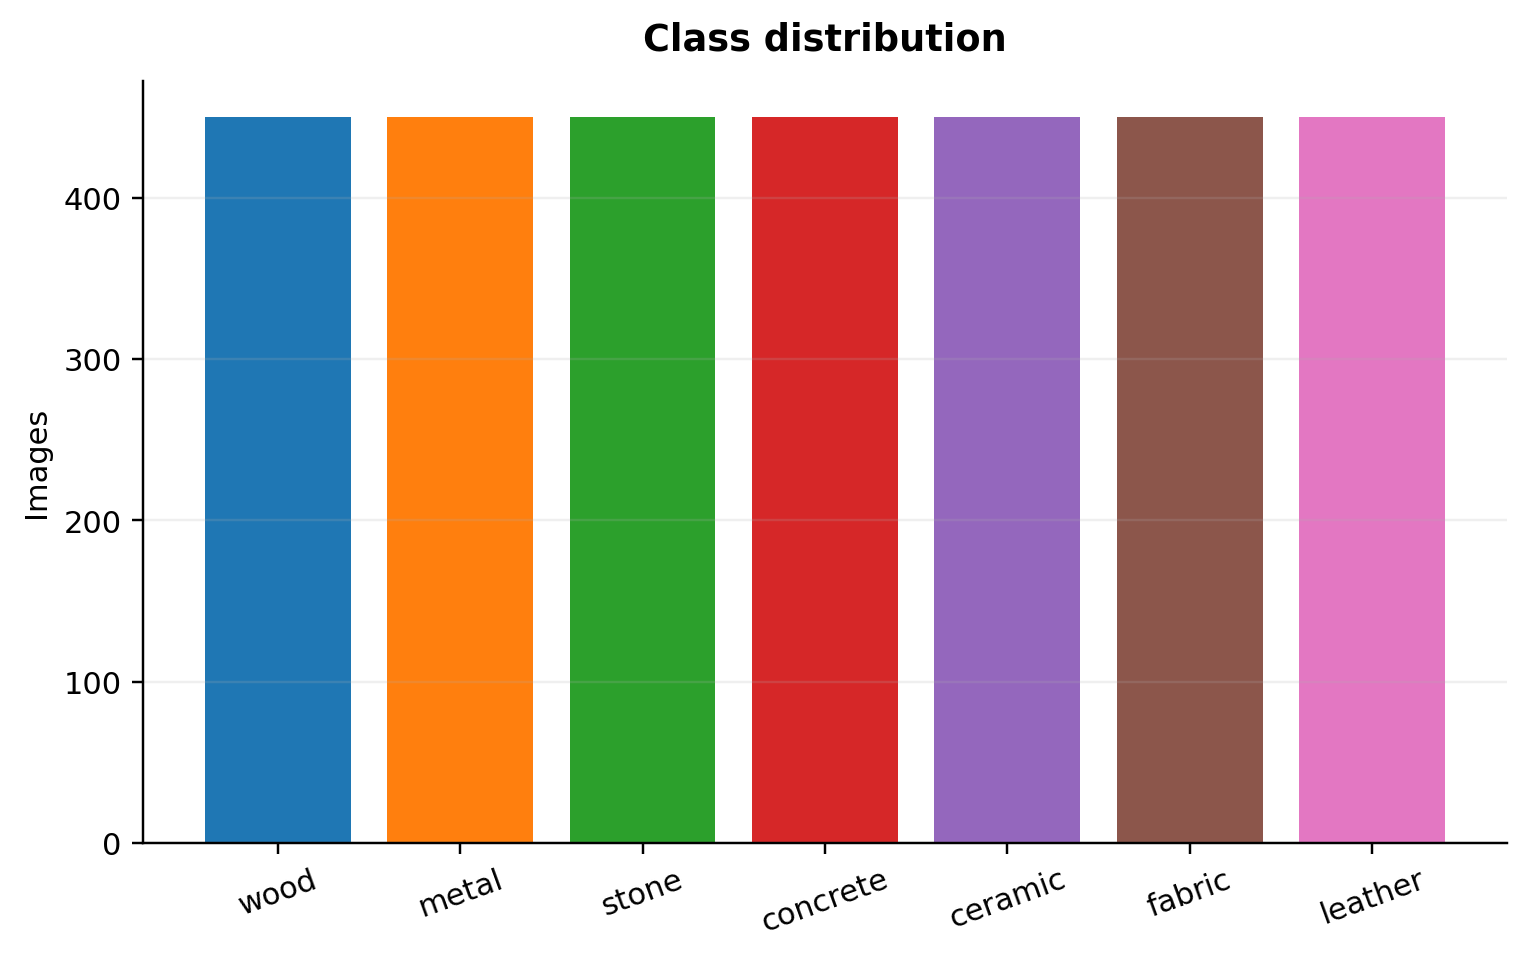

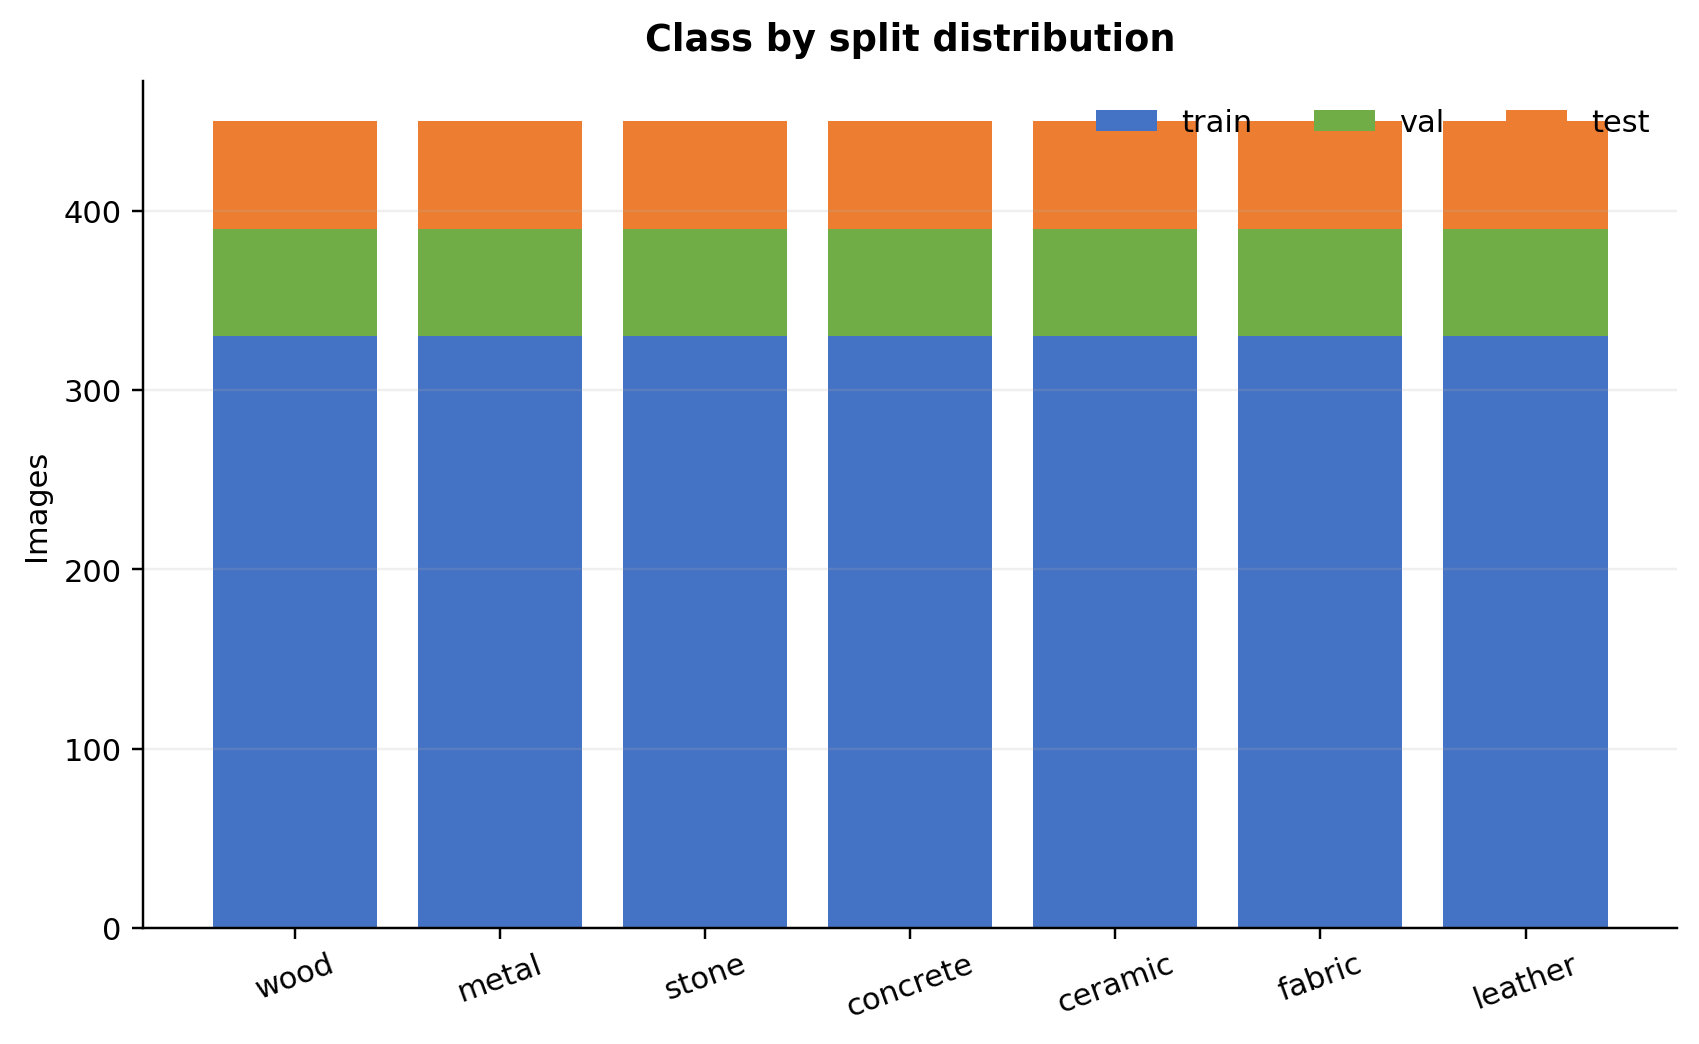

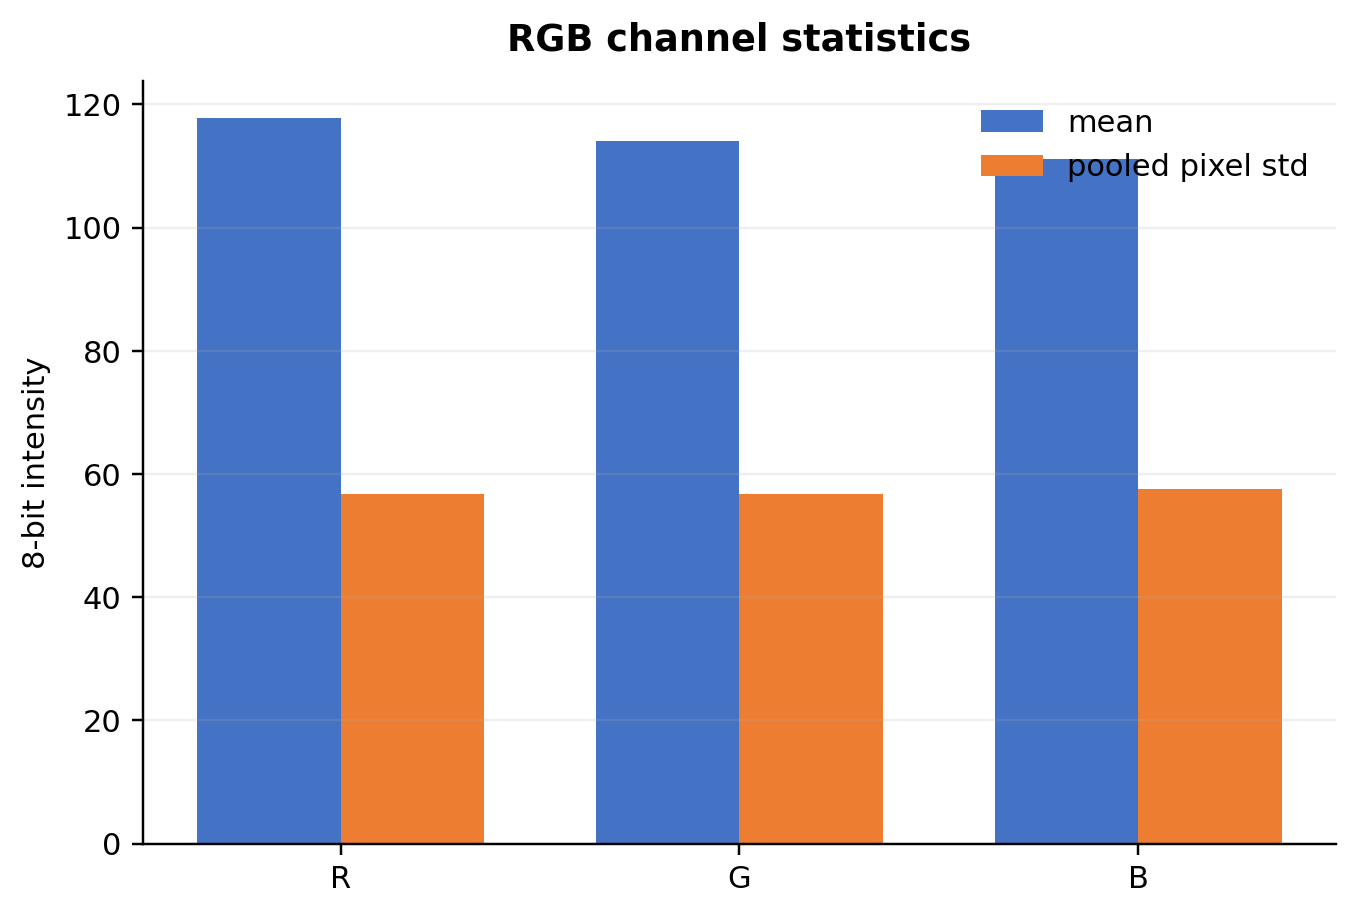

In [6]:
def show_figure(name: str, width: int = 700) -> None:
    path = FIGURE_DIR / name
    assert path.is_file(), path
    display(Image(filename=str(path), width=width))

show_figure('class_distribution.png')
show_figure('class_split_stacked.png')
show_figure('rgb_channel_mean_std.png')

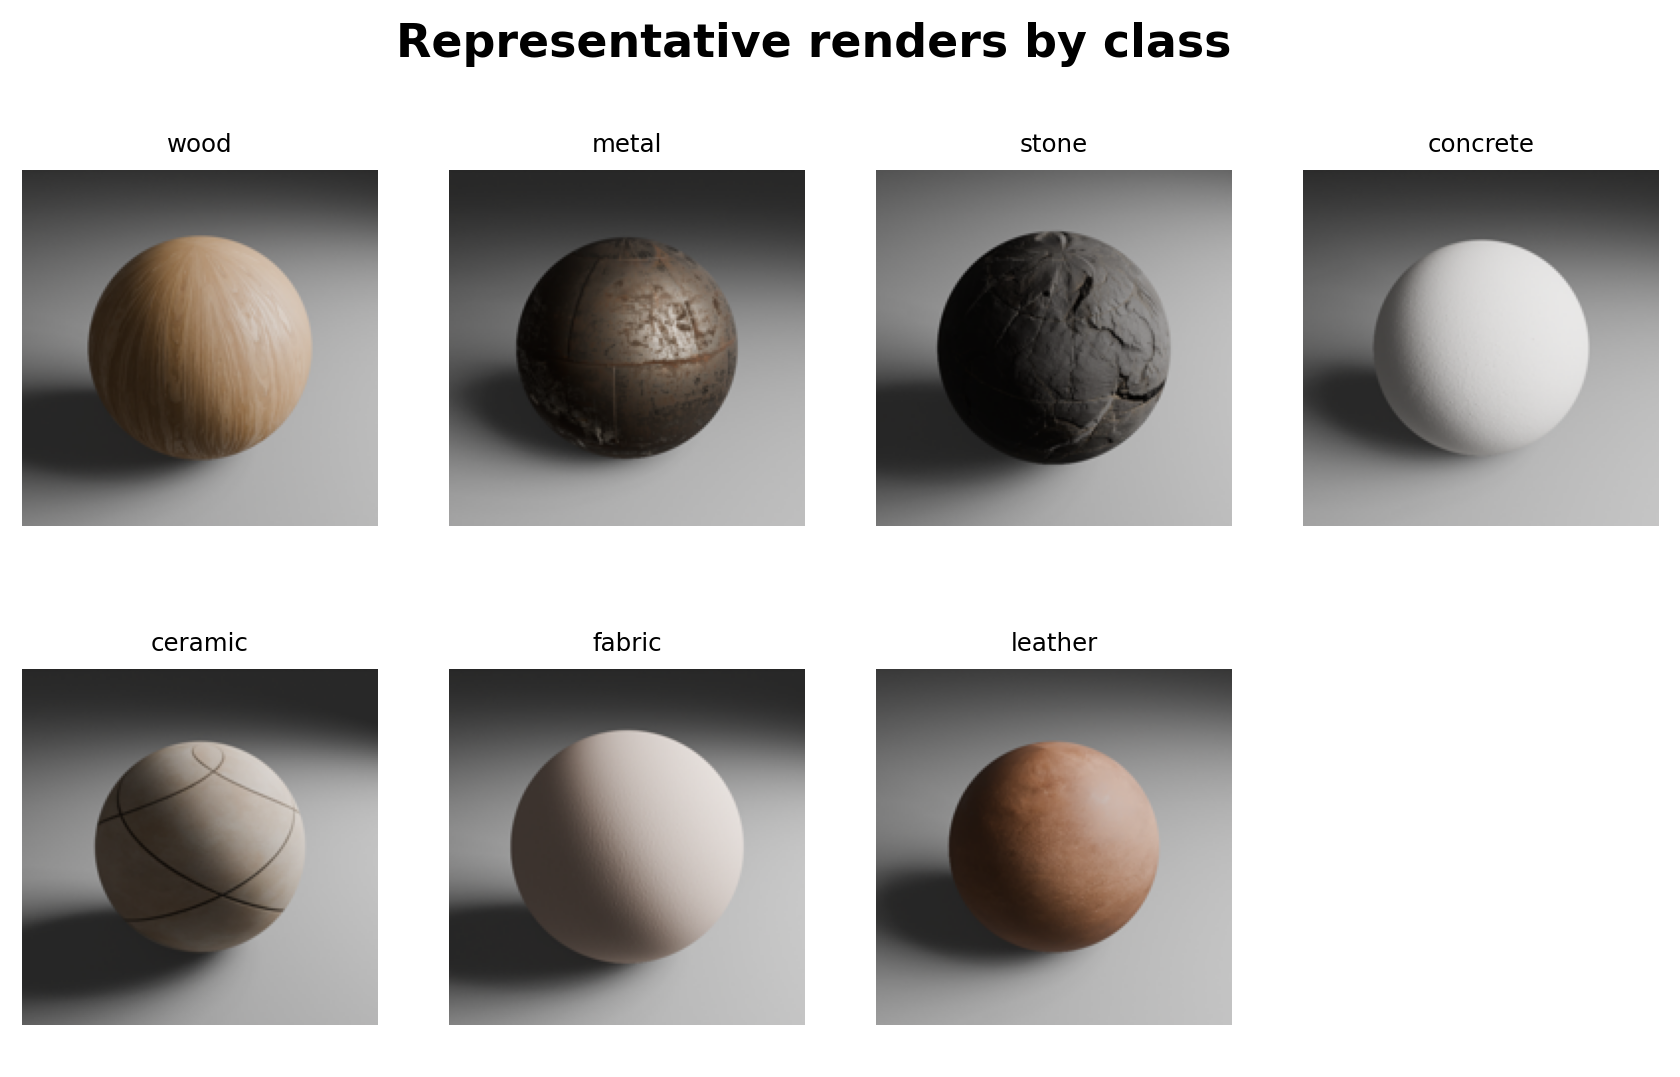

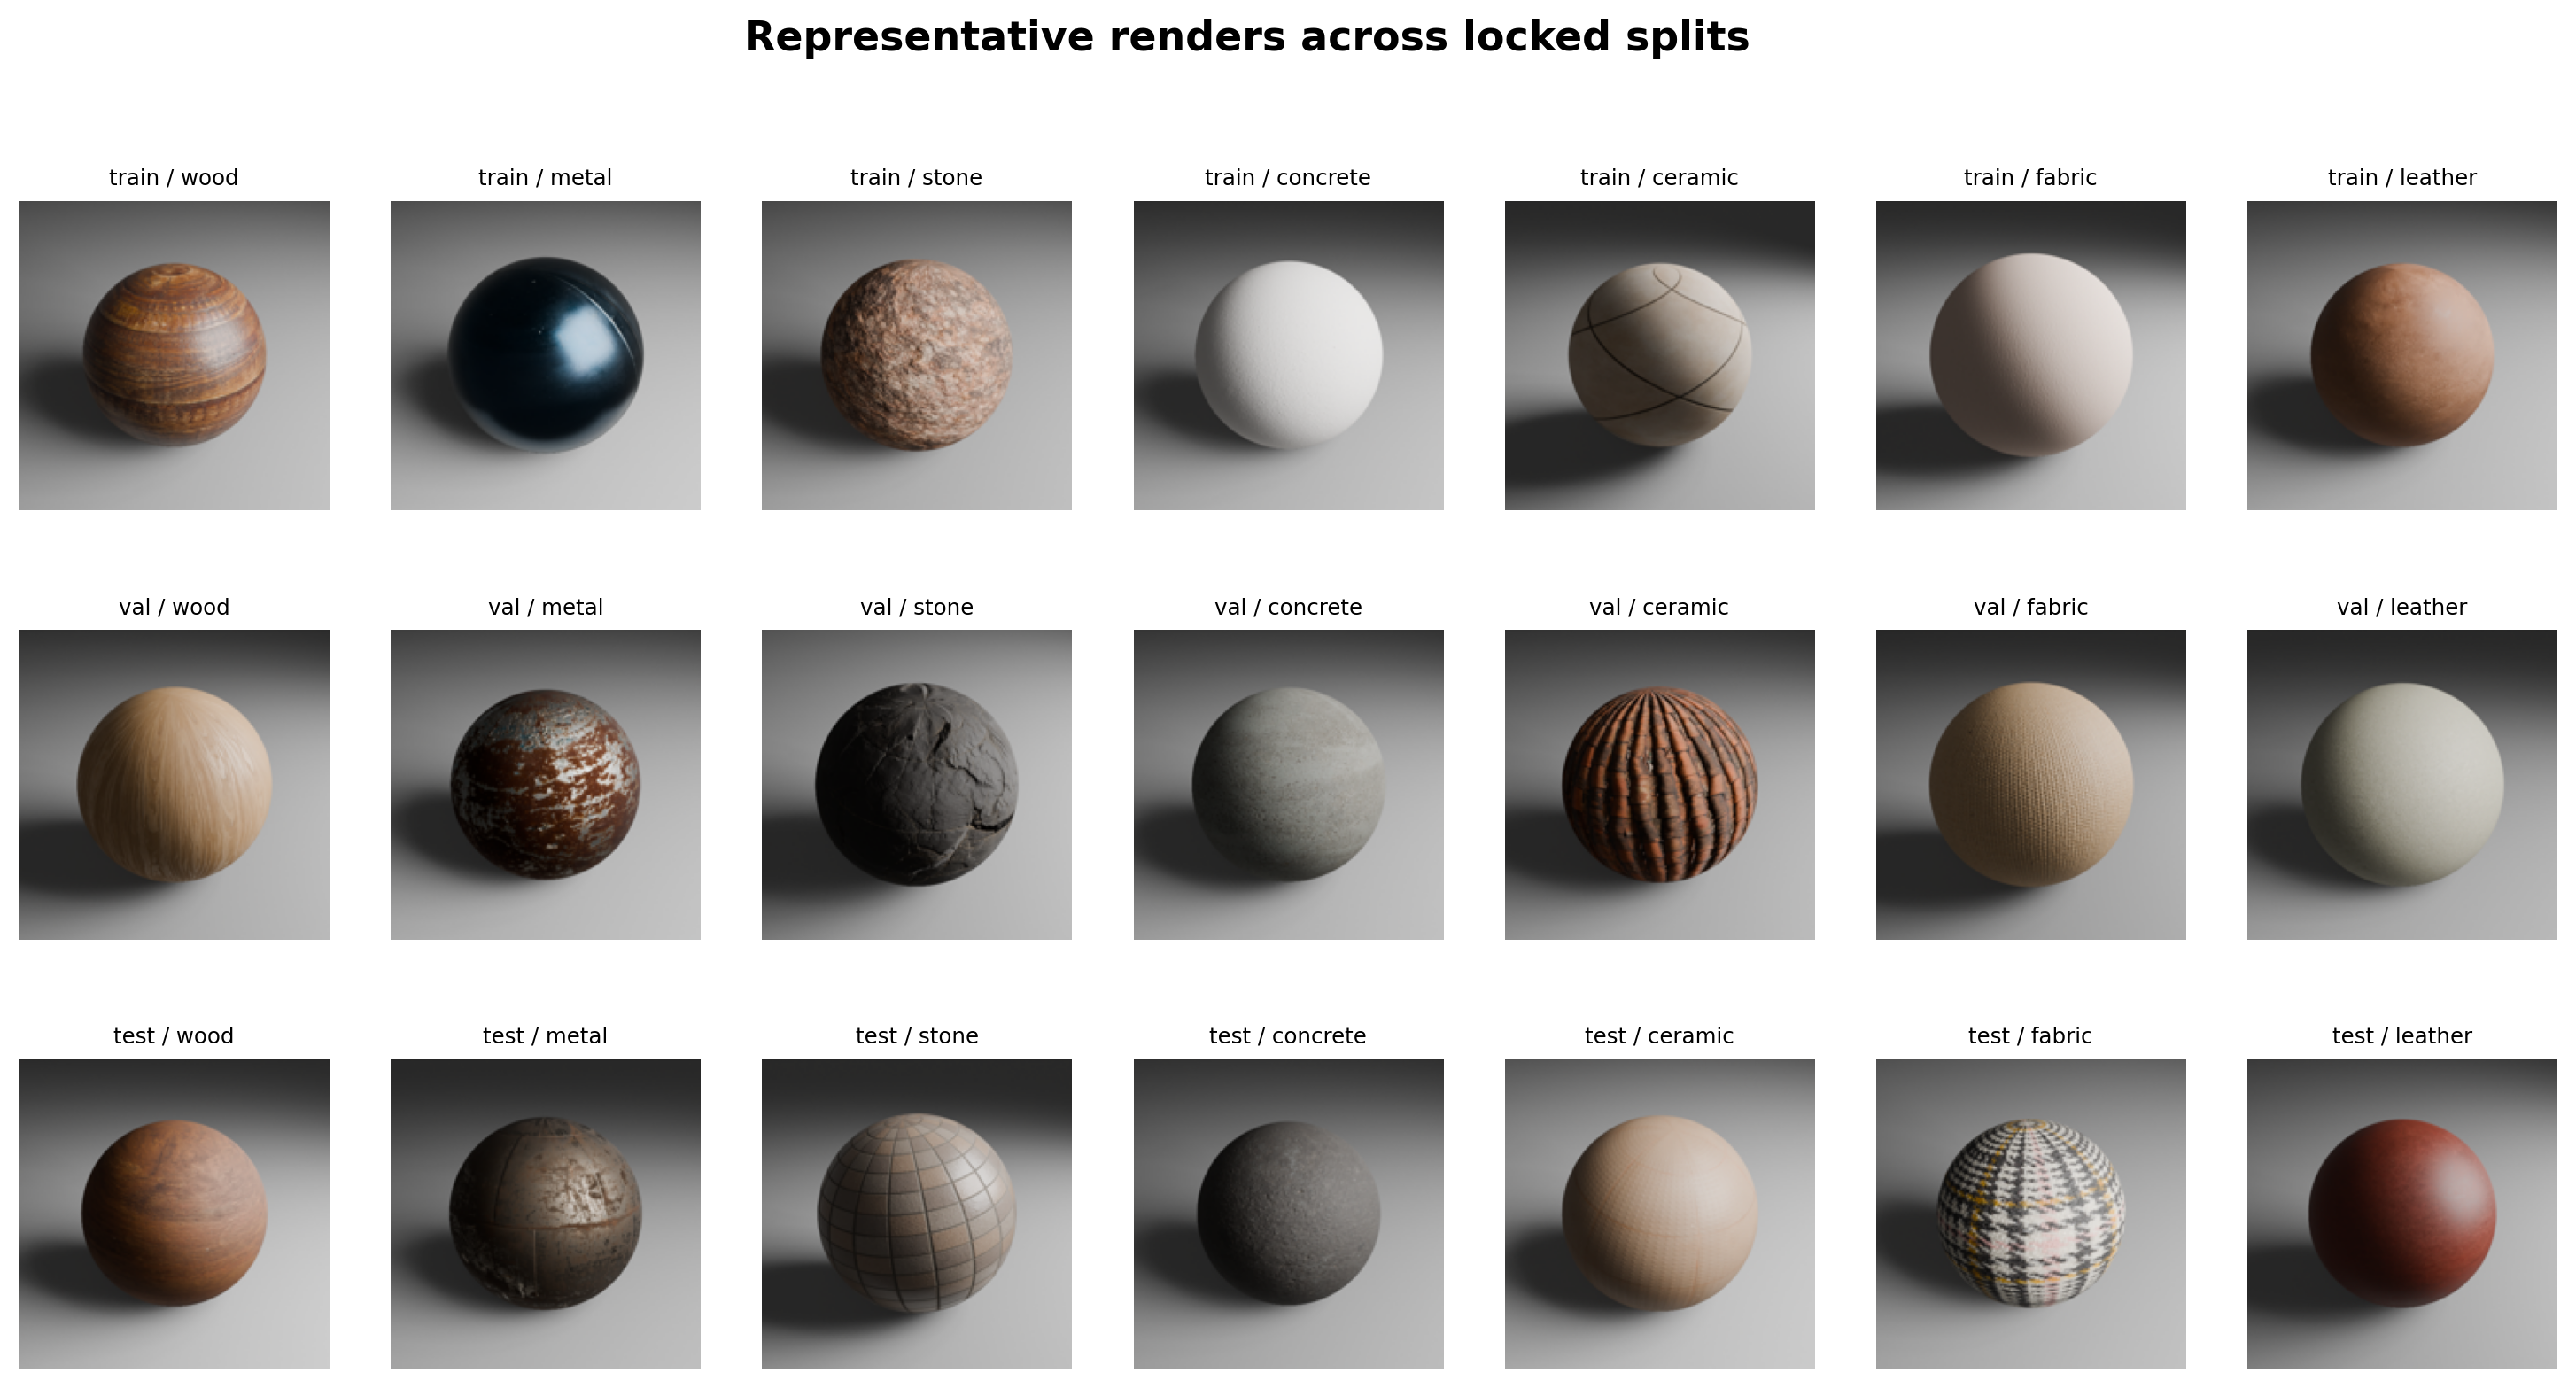

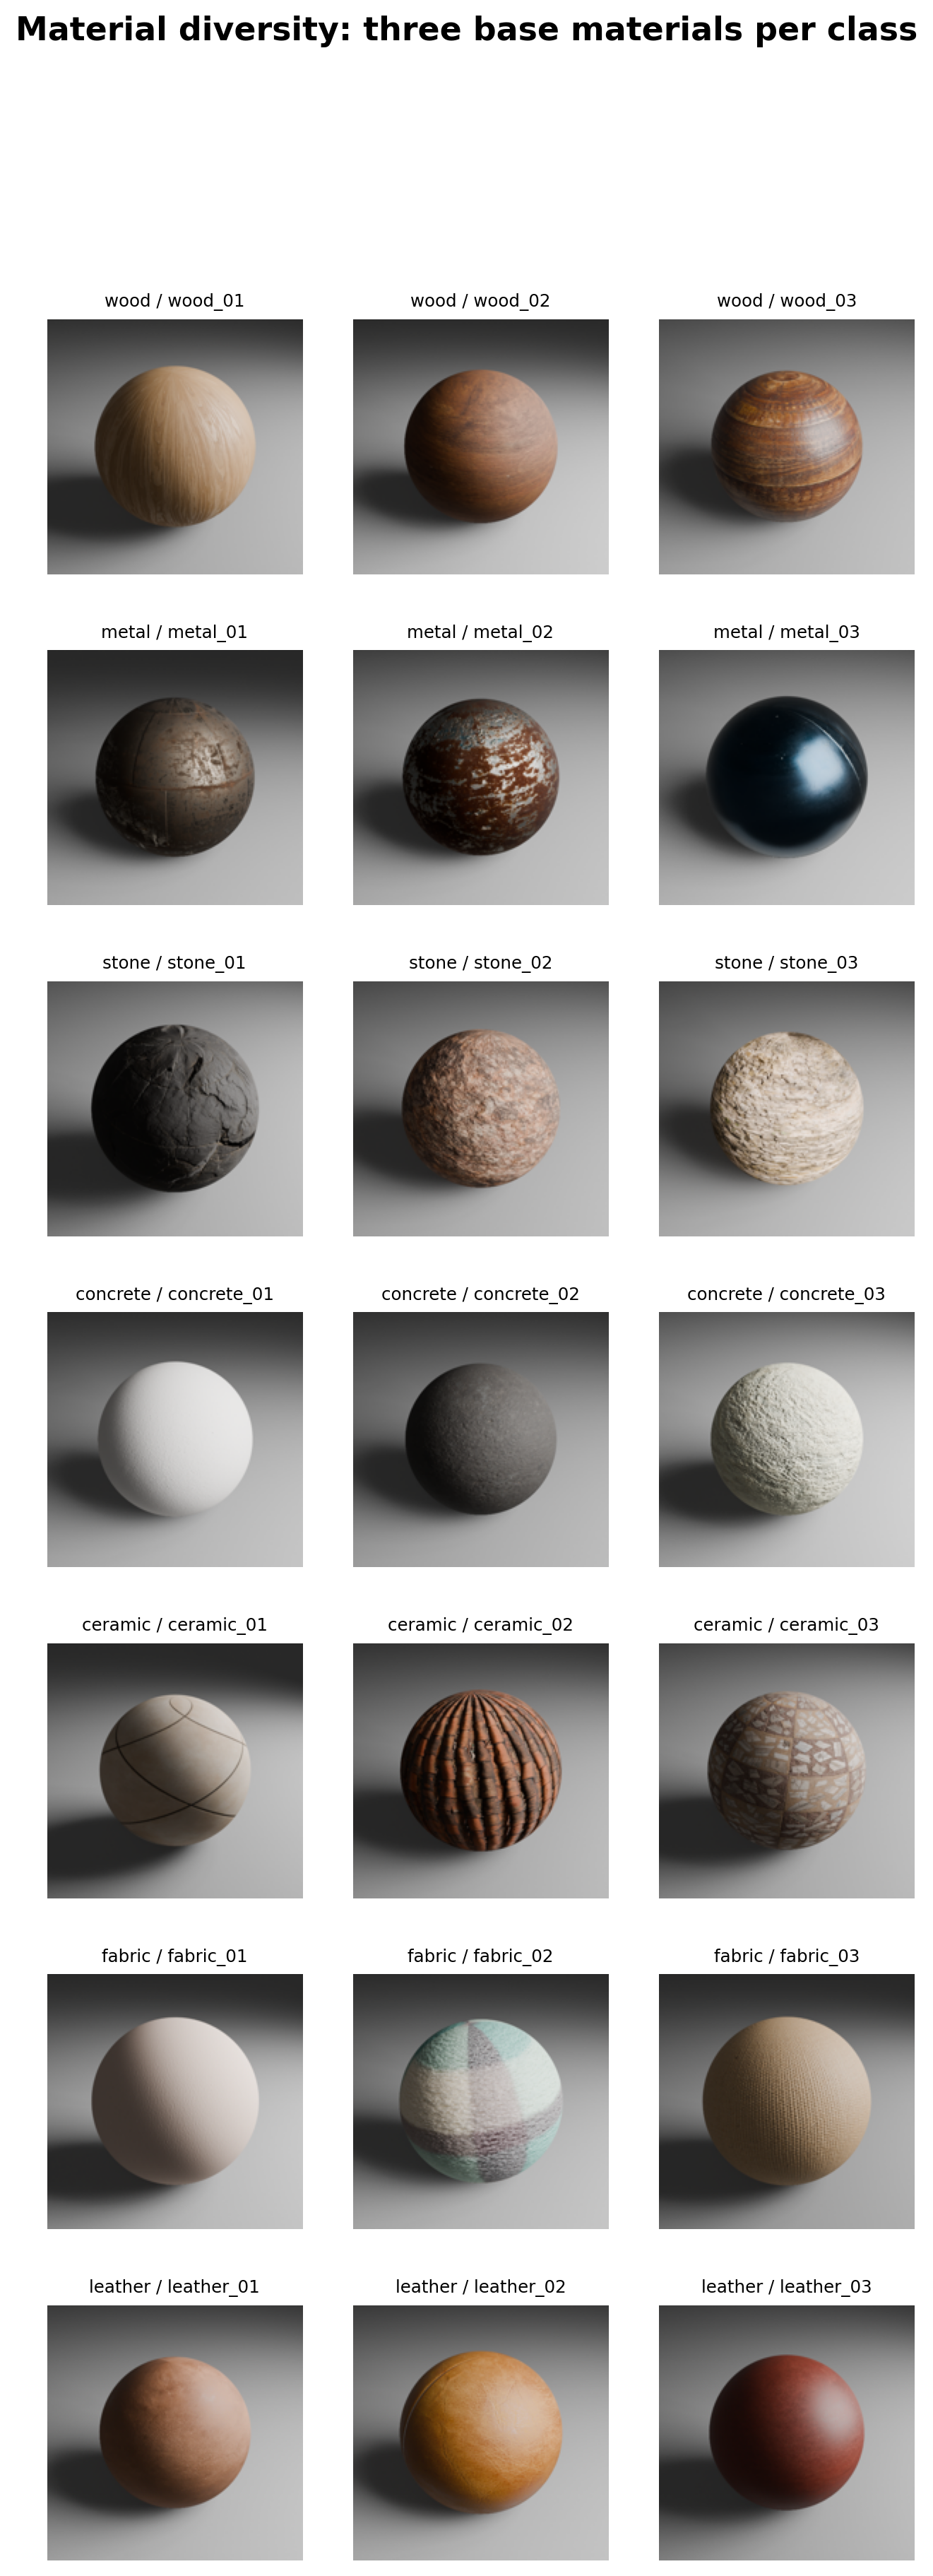

In [7]:
show_figure('representative_images_all_classes.png')
show_figure('representative_images_by_split.png')
show_figure('material_diversity_contact_sheet.png')

## Leakage-safety statement

The locked train/validation/test assignment is at the `material_id` level. All 30 renders for a base material remain in one split, and the verification report asserts that no material crosses splits. This notebook only reports structural QA and descriptive dataset properties; it does not use test labels for model selection, tuning, or performance claims.